##### COMP30027 Machine Learning - Project 2
# Michael Vallen Suryajaya

## Task 1

**Pipeline overview:**
1. Load and explore the data
2. Feature preprocessing
3. Model comparison via cross-validation (provided features)
4. Feature subset analysis
5. Error analysis via confusion matrices
6. ResNet50 feature extraction and comparison
7. Generate Kaggle submission (ResNet50 features)

## 1. Load and explore the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import time

from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(30027)

In [2]:
train_meta = pd.read_csv('data/task1_data/train_metadata.csv')
test_meta  = pd.read_csv('data/task1_data/test_metadata.csv')
color_hist = pd.read_csv('data/task1_data/color_histogram.csv')
hog_pca    = pd.read_csv('data/task1_data/hog_pca.csv')
addl_feats = pd.read_csv('data/task1_data/additional_features.csv')

print('Training instances:', len(train_meta))
print('Test instances:    ', len(test_meta))
print('Classes:', sorted(train_meta['class_name'].unique()))

Training instances: 3750
Test instances:     1250
Classes: ['bird', 'butterfly', 'cat', 'deer', 'dog', 'elephant', 'frog', 'horse', 'sheep', 'spider']


In [3]:
train_meta.head()

,image_id,image_path,class_id,class_name
0,train_bird_00000,images/train/bird/bird_00000.png,0,bird
1,train_bird_00001,images/train/bird/bird_00001.png,0,bird
2,train_bird_00002,images/train/bird/bird_00002.png,0,bird
3,train_bird_00003,images/train/bird/bird_00003.png,0,bird
4,train_bird_00004,images/train/bird/bird_00004.png,0,bird


class_name
bird         375
butterfly    375
cat          375
deer         375
dog          375
elephant     375
frog         375
horse        375
sheep        375
spider       375
Name: count, dtype: int64


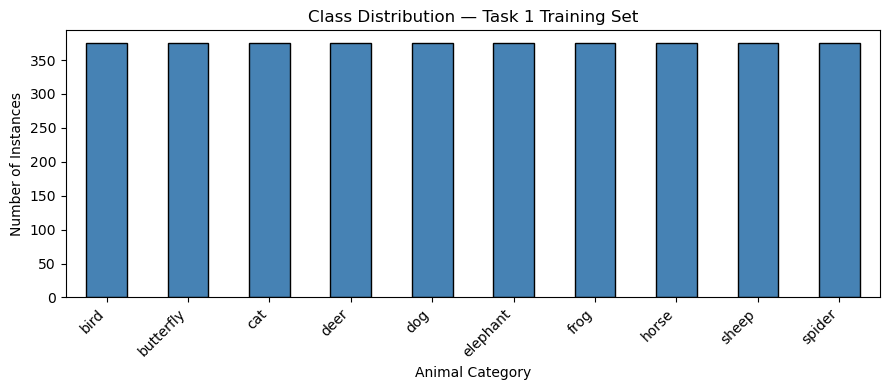

In [4]:
class_counts = train_meta['class_name'].value_counts()
print(class_counts)

class_counts.plot(kind='bar', figsize=(9, 4), color='steelblue', edgecolor='black')
plt.title('Class Distribution — Task 1 Training Set')
plt.xlabel('Animal Category')
plt.ylabel('Number of Instances')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 2. Feature Preprocessing

In [5]:
def split_train_test(df):
    mask = df['image_id'].str.startswith('train')
    return df[mask].copy(), df[~mask].copy()

color_tr, color_te = split_train_test(color_hist)
hog_tr,   hog_te   = split_train_test(hog_pca)
addl_tr,  addl_te  = split_train_test(addl_feats)

train_feats = color_tr.merge(hog_tr, on='image_id').merge(addl_tr, on='image_id')
test_feats  = color_te.merge(hog_te, on='image_id').merge(addl_te, on='image_id')

train_df = train_meta.merge(train_feats, on='image_id')
test_df  = test_meta.merge(test_feats,  on='image_id')

print('train_df shape:', train_df.shape)
print('test_df shape: ', test_df.shape)

train_df shape: (3750, 223)
test_df shape:  (1250, 221)


In [6]:
feat_cols  = [c for c in train_feats.columns if c != 'image_id']
color_cols = [c for c in feat_cols if c.startswith('color')]
hog_cols   = [c for c in feat_cols if c.startswith('hog')]
addl_cols  = [c for c in feat_cols if c.startswith('feat')]

print(f'Features — colour: {len(color_cols)}, HOG: {len(hog_cols)}, additional: {len(addl_cols)}, total: {len(feat_cols)}')

X = train_df[feat_cols].values
y = train_df['class_id'].values
X_test = test_df[feat_cols].values

class_names = train_meta.groupby('class_id')['class_name'].first().sort_index().tolist()
print('Class names:', class_names)

Features — colour: 96, HOG: 100, additional: 23, total: 219
Class names: ['bird', 'butterfly', 'cat', 'deer', 'dog', 'elephant', 'frog', 'horse', 'sheep', 'spider']


In [7]:
scaler = StandardScaler()
X_scaled      = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

print('X_scaled shape:     ', X_scaled.shape)
print('X_test_scaled shape:', X_test_scaled.shape)

X_scaled shape:      (3750, 219)
X_test_scaled shape: (1250, 219)


## 3. Model Comparison via Cross-Validation (Provided Features)

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=30027)

models = [
    ('Zero-R (Baseline)',   DummyClassifier(strategy='most_frequent')),
    ('SVM (RBF)',           SVC(kernel='rbf', C=10, gamma='scale', random_state=30027)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=30027)),
    ('Random Forest',       RandomForestClassifier(n_estimators=100, random_state=30027)),
]

results = {}
for name, model in models:
    start = time.time()
    scores = cross_val_score(model, X_scaled, y, cv=cv, scoring='accuracy')
    elapsed = time.time() - start
    results[name] = scores
    print(f'{name:<25} Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}   (time: {elapsed:.1f}s)')

Zero-R (Baseline)         Accuracy: 0.1000 +/- 0.0000   (time: 0.0s)
SVM (RBF)                 Accuracy: 0.5168 +/- 0.0127   (time: 4.3s)
Logistic Regression       Accuracy: 0.5360 +/- 0.0143   (time: 1.0s)
Random Forest             Accuracy: 0.4995 +/- 0.0132   (time: 8.0s)


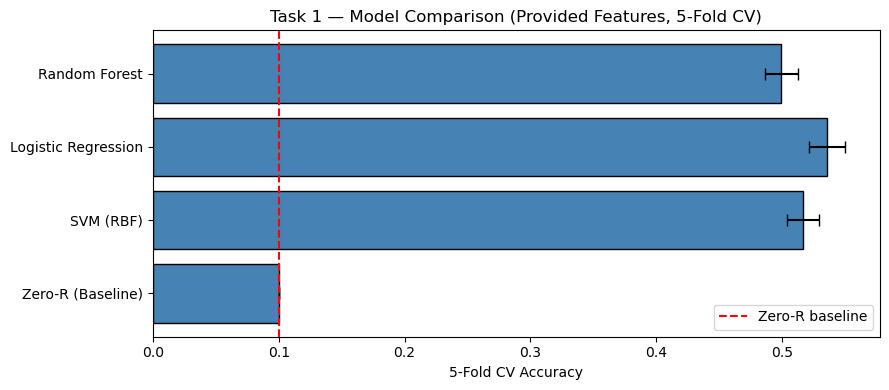

In [9]:
model_names = list(results.keys())
mean_scores = [results[n].mean() for n in model_names]
std_scores  = [results[n].std()  for n in model_names]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(model_names, mean_scores, xerr=std_scores,
        color='steelblue', edgecolor='black', capsize=4)
ax.axvline(x=0.1, color='red', linestyle='--', label='Zero-R baseline')
ax.set_xlabel('5-Fold CV Accuracy')
ax.set_title('Task 1 — Model Comparison (Provided Features, 5-Fold CV)')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Feature Subset Analysis

In [10]:
feature_subsets = [
    ('Colour Histogram only', color_cols),
    ('HOG (PCA) only',        hog_cols),
    ('Additional only',       addl_cols),
    ('All features combined', feat_cols),
]

lr = LogisticRegression(max_iter=1000, random_state=30027)

print('Feature subset analysis — Logistic Regression, 5-fold CV')
print('-' * 55)
for label, cols in feature_subsets:
    X_sub = StandardScaler().fit_transform(train_df[cols].values)
    scores = cross_val_score(lr, X_sub, y, cv=cv, scoring='accuracy')
    print(f'{label:<30}  Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}')

Feature subset analysis — Logistic Regression, 5-fold CV
-------------------------------------------------------
Colour Histogram only           Accuracy: 0.2077 +/- 0.0183
HOG (PCA) only                  Accuracy: 0.4280 +/- 0.0175
Additional only                 Accuracy: 0.4624 +/- 0.0266
All features combined           Accuracy: 0.5360 +/- 0.0143


## 5. Error Analysis — Confusion Matrix (Provided Features)

In [12]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=30027
)

# Logistic Regression — best single model on Task 1 provided features
lr_clf = LogisticRegression(max_iter=1000, random_state=30027)
lr_clf.fit(X_tr, y_tr)
y_pred = lr_clf.predict(X_val)

print('Holdout accuracy:', accuracy_score(y_val, y_pred))
print()
print(classification_report(y_val, y_pred, target_names=class_names))

Holdout accuracy: 0.504

              precision    recall  f1-score   support

        bird       0.44      0.40      0.42        75
   butterfly       0.64      0.56      0.60        75
         cat       0.44      0.36      0.40        75
        deer       0.46      0.52      0.49        75
         dog       0.44      0.43      0.43        75
    elephant       0.56      0.61      0.59        75
        frog       0.51      0.59      0.54        75
       horse       0.53      0.56      0.54        75
       sheep       0.54      0.51      0.52        75
      spider       0.48      0.51      0.49        75

    accuracy                           0.50       750
   macro avg       0.50      0.50      0.50       750
weighted avg       0.50      0.50      0.50       750



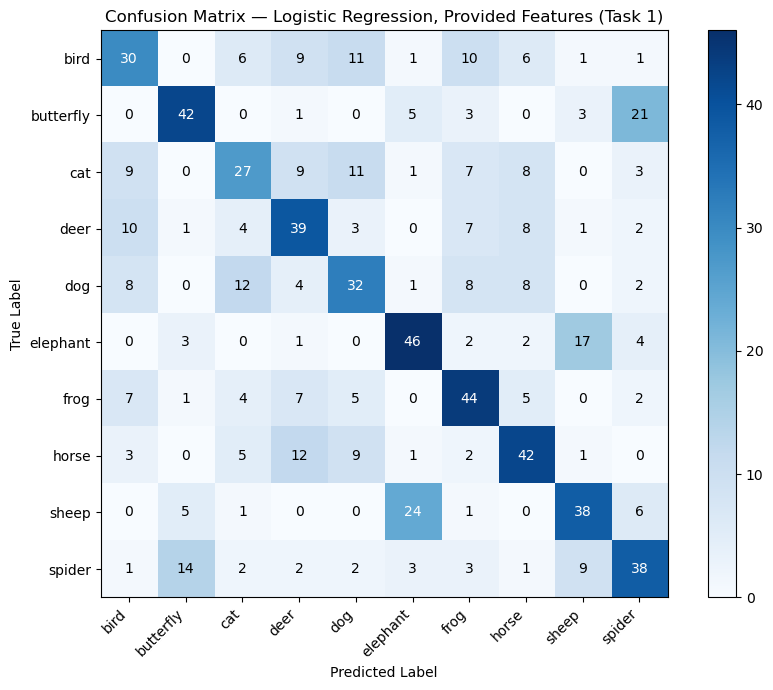

In [13]:
cm = confusion_matrix(y_val, y_pred)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticklabels(class_names)
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='white' if cm[i, j] > thresh else 'black')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
ax.set_title('Confusion Matrix — Logistic Regression, Provided Features (Task 1)')
plt.tight_layout()
plt.show()

In [ ]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)
for name, acc in zip(class_names, per_class_acc):
    print(f'{name:<12}: {acc:.2f}')

## 6. ResNet50 Feature Extraction

The provided features achieve ~55% on Task 1. We now engineer additional features
using a **ResNet50 pretrained on ImageNet** as a generic feature extractor.
This is allowed by the spec since the model was not trained on CIFAR-10 or CUB-200-2011.

ResNet50 extracts **2048-dimensional** feature vectors per image.

**The Kaggle submission will use ResNet50 features.**

In [14]:
import sys
!{sys.executable} -m pip install torch torchvision --quiet

In [15]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import os

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1])
feature_extractor.eval()

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

print('ResNet50 loaded. Output feature dimension: 2048')

ResNet50 loaded. Output feature dimension: 2048


In [17]:
DATA_DIR_T1 = 'data/task1_data/'

def extract_resnet_features(meta_df, base_dir, desc='Extracting'):
    features = []
    for i, row in meta_df.iterrows():
        img_path = os.path.join(base_dir, row['image_path'])
        try:
            img    = Image.open(img_path).convert('RGB')
            tensor = transform(img).unsqueeze(0)
            with torch.no_grad():
                feat = feature_extractor(tensor).squeeze().numpy()
            features.append(feat)
        except Exception as e:
            print(f'  WARNING: {img_path}: {e}')
            features.append(np.zeros(2048))
        if (i + 1) % 500 == 0 or (i + 1) == len(meta_df):
            print(f'  {desc}: {i + 1}/{len(meta_df)} done')
    return np.array(features)


t1_train_path = DATA_DIR_T1 + 'resnet50_train_features.npy'
t1_test_path  = DATA_DIR_T1 + 'resnet50_test_features.npy'

if os.path.exists(t1_train_path) and os.path.exists(t1_test_path):
    print('Loading saved ResNet50 features...')
    X_train_resnet = np.load(t1_train_path)
    X_test_resnet  = np.load(t1_test_path)
else:
    print('Extracting features (5-10 mins on CPU for 5000 images)...')
    X_train_resnet = extract_resnet_features(train_meta, DATA_DIR_T1, 'Train')
    X_test_resnet  = extract_resnet_features(test_meta,  DATA_DIR_T1, 'Test')
    np.save(t1_train_path, X_train_resnet)
    np.save(t1_test_path,  X_test_resnet)
    print('Saved for future runs.')

print(f'Train features: {X_train_resnet.shape}')
print(f'Test features:  {X_test_resnet.shape}')

Extracting features (5-10 mins on CPU for 5000 images)...
  Train: 500/3750 done
  Train: 1000/3750 done
  Train: 1500/3750 done
  Train: 2000/3750 done
  Train: 2500/3750 done
  Train: 3000/3750 done
  Train: 3500/3750 done
  Train: 3750/3750 done
  Test: 500/1250 done
  Test: 1000/1250 done
  Test: 1250/1250 done
Saved for future runs.
Train features: (3750, 2048)
Test features:  (1250, 2048)


## 7. Model Comparison — ResNet50 Features

In [18]:
scaler_r = StandardScaler()
X_r_scaled      = scaler_r.fit_transform(X_train_resnet)
X_r_test_scaled = scaler_r.transform(X_test_resnet)

models_resnet = [
    ('Zero-R (Baseline)',   DummyClassifier(strategy='most_frequent')),
    ('SVM (RBF)',           SVC(kernel='rbf', C=10, gamma='scale', random_state=30027)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=30027)),
    ('Random Forest',       RandomForestClassifier(n_estimators=200, max_features='sqrt', random_state=30027)),
]

results_resnet = {}
print('Task 1 — ResNet50 Features (5-fold CV)')
print('-' * 55)
for name, model in models_resnet:
    start  = time.time()
    scores = cross_val_score(model, X_r_scaled, y, cv=cv, scoring='accuracy')
    elapsed = time.time() - start
    results_resnet[name] = scores
    print(f'{name:<25} Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}   (time: {elapsed:.1f}s)')

Task 1 — ResNet50 Features (5-fold CV)
-------------------------------------------------------
Zero-R (Baseline)         Accuracy: 0.1000 +/- 0.0000   (time: 0.0s)
SVM (RBF)                 Accuracy: 0.8933 +/- 0.0075   (time: 12.4s)
Logistic Regression       Accuracy: 0.8771 +/- 0.0096   (time: 1.5s)
Random Forest             Accuracy: 0.8669 +/- 0.0109   (time: 52.2s)


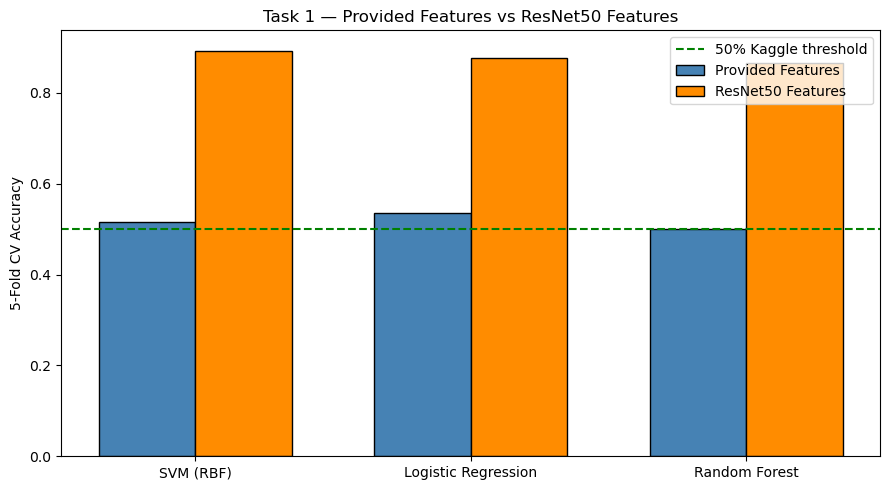

In [19]:
# Side-by-side: provided features vs ResNet50
compare_models = ['SVM (RBF)', 'Logistic Regression', 'Random Forest']
provided_acc   = [results[m].mean()        for m in compare_models]
resnet_acc     = [results_resnet[m].mean() for m in compare_models]

x = np.arange(len(compare_models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, provided_acc, width, label='Provided Features', color='steelblue',  edgecolor='black')
ax.bar(x + width/2, resnet_acc,   width, label='ResNet50 Features', color='darkorange', edgecolor='black')
ax.axhline(y=0.5, color='green', linestyle='--', label='50% Kaggle threshold')
ax.set_xticks(x)
ax.set_xticklabels(compare_models)
ax.set_ylabel('5-Fold CV Accuracy')
ax.set_title('Task 1 — Provided Features vs ResNet50 Features')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Confusion Matrix — ResNet50 Features

In [21]:
X_tr_r, X_val_r, y_tr_r, y_val_r = train_test_split(
    X_r_scaled, y, test_size=0.2, stratify=y, random_state=30027
)

best_resnet_name = max(results_resnet, key=lambda n: results_resnet[n].mean())
print(f'Best model on ResNet features: {best_resnet_name} ({results_resnet[best_resnet_name].mean():.4f})')

best_resnet_clf = dict(models_resnet)[best_resnet_name]
best_resnet_clf.fit(X_tr_r, y_tr_r)
y_pred_r = best_resnet_clf.predict(X_val_r)

print('Holdout accuracy:', accuracy_score(y_val_r, y_pred_r))
print()
print(classification_report(y_val_r, y_pred_r, target_names=class_names))

Best model on ResNet features: SVM (RBF) (0.8933)
Holdout accuracy: 0.892

              precision    recall  f1-score   support

        bird       0.84      0.84      0.84        75
   butterfly       0.96      0.96      0.96        75
         cat       0.81      0.76      0.79        75
        deer       0.78      0.83      0.80        75
         dog       0.84      0.87      0.86        75
    elephant       0.97      0.99      0.98        75
        frog       0.91      0.95      0.93        75
       horse       0.87      0.81      0.84        75
       sheep       0.96      0.97      0.97        75
      spider       0.97      0.95      0.96        75

    accuracy                           0.89       750
   macro avg       0.89      0.89      0.89       750
weighted avg       0.89      0.89      0.89       750



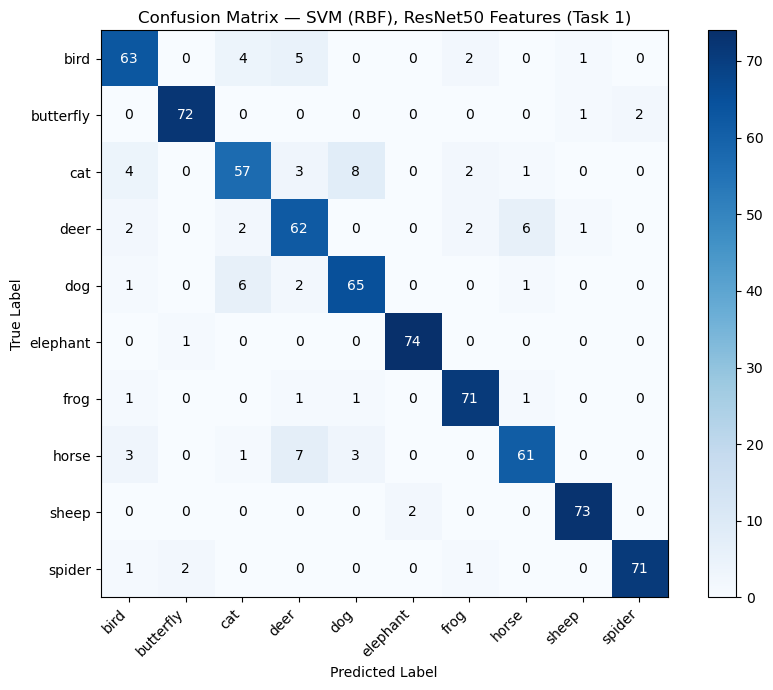

In [22]:
cm_r = confusion_matrix(y_val_r, y_pred_r)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm_r, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticklabels(class_names)
thresh = cm_r.max() / 2.0
for i in range(cm_r.shape[0]):
    for j in range(cm_r.shape[1]):
        ax.text(j, i, str(cm_r[i, j]), ha='center', va='center',
                color='white' if cm_r[i, j] > thresh else 'black')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
ax.set_title(f'Confusion Matrix — {best_resnet_name}, ResNet50 Features (Task 1)')
plt.tight_layout()
plt.show()

In [ ]:
per_class_acc_r = cm_r.diagonal() / cm_r.sum(axis=1)
for name, acc in zip(class_names, per_class_acc_r):
    print(f'{name:<12}: {acc:.2f}')

## 9. Generate Kaggle Submission (ResNet50 Features)

In [23]:
final_clf_t1 = dict(models_resnet)[best_resnet_name]
final_clf_t1.fit(X_r_scaled, y)
test_preds_t1 = final_clf_t1.predict(X_r_test_scaled)

id_to_name = train_meta.groupby('class_id')['class_name'].first().to_dict()

submission_t1 = pd.DataFrame({
    'image_id': test_df['image_id'].values,
    'class_id': test_preds_t1
})
submission_t1['class_name'] = submission_t1['class_id'].map(id_to_name)

print(f'Submission model: {best_resnet_name} (ResNet50 features)')
print(submission_t1.head(10))
print()
print('Prediction distribution:')
print(submission_t1['class_name'].value_counts())

Submission model: SVM (RBF) (ResNet50 features)
     image_id  class_id class_name
0  test_00000         9     spider
1  test_00001         9     spider
2  test_00002         9     spider
3  test_00003         7      horse
4  test_00004         7      horse
5  test_00005         5   elephant
6  test_00006         8      sheep
7  test_00007         3       deer
8  test_00008         6       frog
9  test_00009         4        dog

Prediction distribution:
class_name
cat          139
spider       128
sheep        127
deer         125
bird         125
elephant     124
dog          123
butterfly    123
frog         119
horse        117
Name: count, dtype: int64


In [24]:
submission_t1[['image_id', 'class_id']].to_csv('task1_submission.csv', index=False)
print('Saved task1_submission.csv')

Saved task1_submission.csv
